## 1. Importation des bibliothèques fondamentales

- **Objectif** : Charger les librairies de base indispensables pour la manipulation des données (Pandas, NumPy) et la création de visualisations (Matplotlib, Seaborn).

In [31]:
# Importation des bibliothèques fondamentales
import matplotlib.pyplot as np
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import squarify

print("✅ Bibliothèques importées avec succès !")

✅ Bibliothèques importées avec succès !


## 1.1 Ingestion des données brutes
Nous chargeons ici nos fichiers sources. 

In [32]:
Sales = pd.read_csv("Sales_cleaned_silver.csv")
print("Importation du fichier avec succès")

Importation du fichier avec succès


## 2. Configuration du Design System (Charte Graphique B2B)

- **Objectif** : Définir les variables globales de couleurs, les styles d'axes et la typographie pour garantir une identité visuelle professionnelle et cohérente sur tous les graphiques.

In [33]:
# ==========================================
# DESIGN SYSTEM / CHARTE GRAPHIQUE B2B
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Palette de couleurs sémantiques
PRIMARY_COLOR = "#1F4E79"    # Bleu marine corporate (barres principales, tendances)
ACCENT_COLOR = "#D35400"     # Orange corail / Ambre (mise en avant, alertes, records)
SECONDARY_COLOR = "#3498DB"  # Bleu clair / Turquoise (comparaisons, catégories)
GRAY_SLATE = "#7F8C8D"       # Gris ardoise (éléments secondaires)
TEXT_COLOR = "#2C3E50"       # Gris foncé / Noir doux pour les textes et titres
GRID_COLOR = "#E2E8F0"       # Gris très clair pour les grilles épurées

# Palette globale pour les graphiques multi-catégories (camemberts, barplots...)
COLOR_PALETTE = [PRIMARY_COLOR, ACCENT_COLOR, SECONDARY_COLOR, GRAY_SLATE]

# 2. Configuration globale de Matplotlib & Seaborn
sns.set_theme(style="whitegrid")  # Fond blanc avec grilles horizontales légères

# 3. Paramètres globaux (rcParams) - Tout s'applique automatiquement !
plt.rcParams.update({
    # Dimensions et résolution par défaut
    "figure.figsize": (12, 6),
    "figure.dpi": 300,
    
    # Polices et couleurs globales
    "font.family": "sans-serif",
    "text.color": TEXT_COLOR,
    "axes.labelcolor": TEXT_COLOR,
    "axes.titlecolor": TEXT_COLOR,
    "xtick.color": TEXT_COLOR,
    "ytick.color": TEXT_COLOR,
    
    # Tailles et graisses automatiques (Finit les .fontsize à répéter !)
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.labelweight": "bold",
    
    # Style de la grille et des axes
    "axes.edgecolor": GRID_COLOR,
    "axes.linewidth": 1.0,
    "grid.color": GRID_COLOR,
    "grid.linestyle": "--",
    "grid.alpha": 0.6,
    
    # Style des lignes par défaut (pour les lineplots)
    "lines.linewidth": 2.5,
    "lines.markersize": 7,
})

print("🎨 Design System complet appliqué avec succès !")

🎨 Design System complet appliqué avec succès !


Markdown
## 📊 Tableau de Bord : KPIs et Objectifs Stratégiques

Cette section regroupe les indicateurs clés de performance (KPIs) essentiels pour le pilotage commercial et l'analyse de la valeur client.

### 1. Indicateurs Clés de Performance (KPIs) Globaux

* **Chiffre d'Affaires Total (CA) :** Somme globale des revenus générés sur la période.
* **Nombre de Clients Actifs :** Volume total de clients uniques ayant passé au moins une commande.
* **Panier Moyen (Average Order Value - AOV) :** Montant moyen dépensé par commande ($CA / Nombre de commandes$).
* **Fréquence d'Achat :** Nombre moyen de commandes par client.
* **Quantité Totale Vendue :** Volume total d'articles écoulés.

In [34]:
print("--- Analyse du Chiffre d'Affaires par Client ---")

# 1. Calculer le CA total par client
ca_total_clients = Sales.groupby("CompanyName")["TotalPrice"].sum().reset_index()

# 2. Calculer le pourcentage de chaque client par rapport au CA global
ca_total_clients["pourcentage %"] = (ca_total_clients['TotalPrice'] / ca_total_clients['TotalPrice'].sum()) * 100

# 3. Trier du plus grand au plus petit pour voir les meilleurs clients en premier
ca_total_clients = ca_total_clients.sort_values(by='TotalPrice', ascending=False).reset_index(drop=True)

# 4. Formater l'affichage (Montant en € et pourcentage avec 2 décimales)
ca_total_clients['TotalPrice_formatted'] = ca_total_clients['TotalPrice'].map('{:,.2f} €'.format)
ca_total_clients['pourcentage_formatted'] = ca_total_clients['pourcentage %'].map('{:.2f} %'.format)

# Sélectionner et renommer les colonnes propres pour l'affichage
tableau_final = ca_total_clients[['CompanyName', 'TotalPrice_formatted', 'pourcentage_formatted']]
tableau_final.columns = ['Client', 'Chiffre d\'Affaires', 'Part du CA (%)']

print("Tableau de la répartition du Chiffre d'Affaires par client :")
# Affichage du tableau final
display(tableau_final)

--- Analyse du Chiffre d'Affaires par Client ---
Tableau de la répartition du Chiffre d'Affaires par client :


,Client,Chiffre d'Affaires,Part du CA (%)
0,DataWorks,"328,146.00 €",13.68 %
1,GreenTech,"325,734.00 €",13.58 %
2,TechCorp,"324,835.00 €",13.55 %
3,AI Systems,"312,777.00 €",13.04 %
4,CyberSecure,"309,488.00 €",12.91 %
5,NextGen Consulting,"283,440.00 €",11.82 %
6,InnovaSolutions,"266,158.00 €",11.10 %
7,CloudNet,"247,392.00 €",10.32 %


### 📊 Analyse du Chiffre d'Affaires par Client : Évaluation de la Dépendance et du Risque Financier

---

#### 1. Constat Général : Une Répartition Homogène du Chiffre d'Affaires
* **Part de marché équilibrée :** La répartition du Chiffre d'Affaires (CA) entre les principaux clients est remarquablement homogène, chaque client contribuant à hauteur de **10 % à 14 %** du CA global.
* **Absence de "Client Roi" :** Aucun client ne monopolise l'activité de l'entreprise (pas de poids écrasant supérieur à 20-30 %).

---

#### 2. Segmentation du Portefeuille Client (3 Groupes)
Bien que la structure globale soit équilibrée, une segmentation fine en **trois catégories** se dégage :

1. **Top Performers (> 13 % du CA) :** *DataWorks, GreenTech, TechCorp, AI Systems*
   * Génèrent à eux seuls près de la moitié du CA global.
   * Constituent le socle de rentabilité stratégique de l'entreprise.
2. **Cœur de Cible (11 % à 12 % du CA) :** *CyberSecure, NextGen Consulting, InnovaSolutions*
   * Apportent un volume d'affaires récurrent et stable, indispensable à l'équilibre financier.
3. **Base de Soutien (≈ 10 % du CA) :** *CloudNet*
   * Participe activement à l'assiette du CA, avec un potentiel de montée en gamme (upselling).

---

#### 3. Enjeux Business & Diagnostic Stratégique
* **Résilience et Faible Risque de Concentration :** La perte éventuelle d'un client majeur n'absorberait au maximum que ~13,7 % des revenus, évitant ainsi un risque de faillite ou de déstabilisation brutale.
* **Prochaine Étape (Mise en Perspective BI) :**
  > *Cette stabilité financière traduit-elle une régularité dans les achats ou de grosses commandes ponctuelles ?*  
  > L'analyse croisée avec les **volumes vendus (quantités)** et la **fréquence d'achat (nombre de commandes uniques)** permettra de valider si ces clients à fort CA sont également les plus réguliers.

In [35]:
print("--- Analyse des Volumes Vendus par Client ---")

# 1. Calculer le nombre d'articles total par client
volume_clients = Sales.groupby("CompanyName")["Quantity"].sum().reset_index()

# 2. Calculer le pourcentage de chaque client par rapport au volume global
volume_clients["pourcentage %"] = (volume_clients["Quantity"] / volume_clients["Quantity"].sum()) * 100

# 3. Trier du plus grand au plus petit
volume_clients = volume_clients.sort_values(by="Quantity", ascending=False).reset_index(drop=True)

# 4. Formatage propre pour l'affichage
volume_clients["pourcentage_formatted"] = volume_clients["pourcentage %"].map("{:.2f} %".format)

# Sélection des colonnes pour la présentation finale
tableau_quantites = volume_clients[["CompanyName", "Quantity", "pourcentage_formatted"]]
tableau_quantites.columns = ["Client", "Quantité Totale Vendue", "Part du Volume (%)"]

print("Tableau de la répartition des quantités commandées par client :")
display(tableau_quantites)

--- Analyse des Volumes Vendus par Client ---
Tableau de la répartition des quantités commandées par client :


,Client,Quantité Totale Vendue,Part du Volume (%)
0,TechCorp,434,13.96 %
1,GreenTech,416,13.38 %
2,AI Systems,411,13.22 %
3,CyberSecure,409,13.16 %
4,DataWorks,398,12.80 %
5,InnovaSolutions,369,11.87 %
6,NextGen Consulting,346,11.13 %
7,CloudNet,326,10.49 %


### 📦 Analyse des Quantités Vendues par Client : Cohérence et Mix Produit

---

#### 1. Constat Général : Une Stabilité Confirmée en Volume
* **Partage équitable du volume :** À l'image du Chiffre d'Affaires, la répartition des articles commandés s'étale de **10,49 % à 13,96 %**. 
* **Alignement global :** Le quatuor de tête en volume reste très proche de celui du CA, confirmant que les plus gros acheteurs en valeur sont aussi ceux qui mobilisent le plus les stocks de l'entreprise.

---

#### 2. Zoom Stratégique : Le Décalage de *DataWorks*
* **Le cas DataWorks :** Numéro **1 absolu en Chiffre d'Affaires** (13,68 %), DataWorks descend à la **5ème place en volume** (12,80 %). 
* **Interprétation Business (Panier et Mix) :** Ce léger décalage est un indicateur fort : DataWorks achète un volume légèrement plus faible d'articles, mais ceux-ci ont une valeur unitaire (ou un panier) plus élevée. C'est un profil de client potentiellement orienté vers des produits à plus forte valeur ajoutée.

---

#### 3. Prochaine Étape (Fréquence d'achat)
> *Cette régularité dans les volumes s'accompagne-t-elle d'une fréquence de commande similaire ?*  
> L'analyse du nombre de commandes uniques permettra de départager les clients en termes de récurrence.

In [36]:
print("--- Analyse des commandes par Client ---")

# 1. Calculer le nombre de commandes uniques par client
commandes_clients = Sales.groupby("CompanyName")["OrderID"].nunique().reset_index()

# 2. Calculer le pourcentage de chaque client par rapport aux commandes globales
commandes_clients["pourcentage %"] = (commandes_clients["OrderID"] / commandes_clients["OrderID"].sum()) * 100

# 3. Trier du plus grand au plus petit
commandes_clients = commandes_clients.sort_values(by="OrderID", ascending=False).reset_index(drop=True)

# 4. Formatage propre pour l'affichage
commandes_clients["pourcentage_formatted"] = commandes_clients["pourcentage %"].map("{:.2f} %".format)

# Sélection des colonnes pour la présentation finale (adapté aux commandes)
tableau_commandes = commandes_clients[["CompanyName", "OrderID", "pourcentage_formatted"]]
tableau_commandes.columns = ["Client", "Nombre de Commandes", "Part des Commandes (%)"]

print("Tableau de la répartition du nombre de commandes par client :")
display(tableau_commandes)

--- Analyse des commandes par Client ---
Tableau de la répartition du nombre de commandes par client :


,Client,Nombre de Commandes,Part des Commandes (%)
0,CyberSecure,69,13.80 %
1,TechCorp,68,13.60 %
2,AI Systems,65,13.00 %
3,GreenTech,65,13.00 %
4,NextGen Consulting,62,12.40 %
5,CloudNet,61,12.20 %
6,DataWorks,56,11.20 %
7,InnovaSolutions,54,10.80 %


### 🔄 Analyse de la Fréquence d'Achat : Récurrence et Habitudes Clients

---

#### 1. Constat Général : Une Homogénéité Toujours Présente... mais avec des Nuances
* **Activité régulière :** Le nombre de commandes oscille entre **10,80 % et 13,80 %** du total des commandes. Aucun client ne s'effondre ou n'explose totalement en termes de nombre de passages de commandes.
* **Le sommet du podium :** C'est *CyberSecure* qui mène la danse en termes de fréquence (69 commandes), suivi de très près par *TechCorp* (68 commandes).

---

#### 2. Zoom Stratégique : Le Paradoxe de *DataWorks* (La Valeur vs La Fréquence)
* **DataWorks (Rappel) :** N°1 en CA, N°5 en volume, mais **N°7 en nombre de commandes** (56 commandes seulement).
* **Diagnostic Business Profond :** 
  * DataWorks ne commande pas souvent, mais **lorsqu'ils commandent, les paniers sont beaucoup plus lourds et massifs**. 
  * À l'inverse, des clients comme *CyberSecure* commandent beaucoup plus souvent, mais pour des volumes/montants unitaires plus éclatés.
* **Typologie client :** On commence à deviner deux profils distincts : les clients "grands comptes / achats groupés" (peu de commandes, fort impact) et les clients "flux tendus / récurrents" (fréquence élevée, commandes plus lisses).

---

#### 3. Conclusion de la Phase Spécifique Client
Ces trois tableaux croisés (CA, Quantités, Commandes) prouvent que le portefeuille d'EOLE est **sain, diversifié et structurellement solide**, tout en abritant des comportements d'achat subtilement différents selon les comptes.


### 🗺️ Visualisation Avancée : Treemap du Chiffre d'Affaires par Client

* **Objectif de la visualisation :** Remplacer les représentations classiques (camemberts ou barres) par une **Treemap** (carte proportionnelle). Cela permet de visualiser instantanément le poids relatif de chaque client sous forme de surfaces géométriques proportionnelles à leur Chiffre d'Affaires.
* **Intérêt Business :** Offrir une lecture visuelle immédiate et percutante pour un comité de direction ou un public non technique, en évitant la surcharge cognitive des tableaux chiffrés.

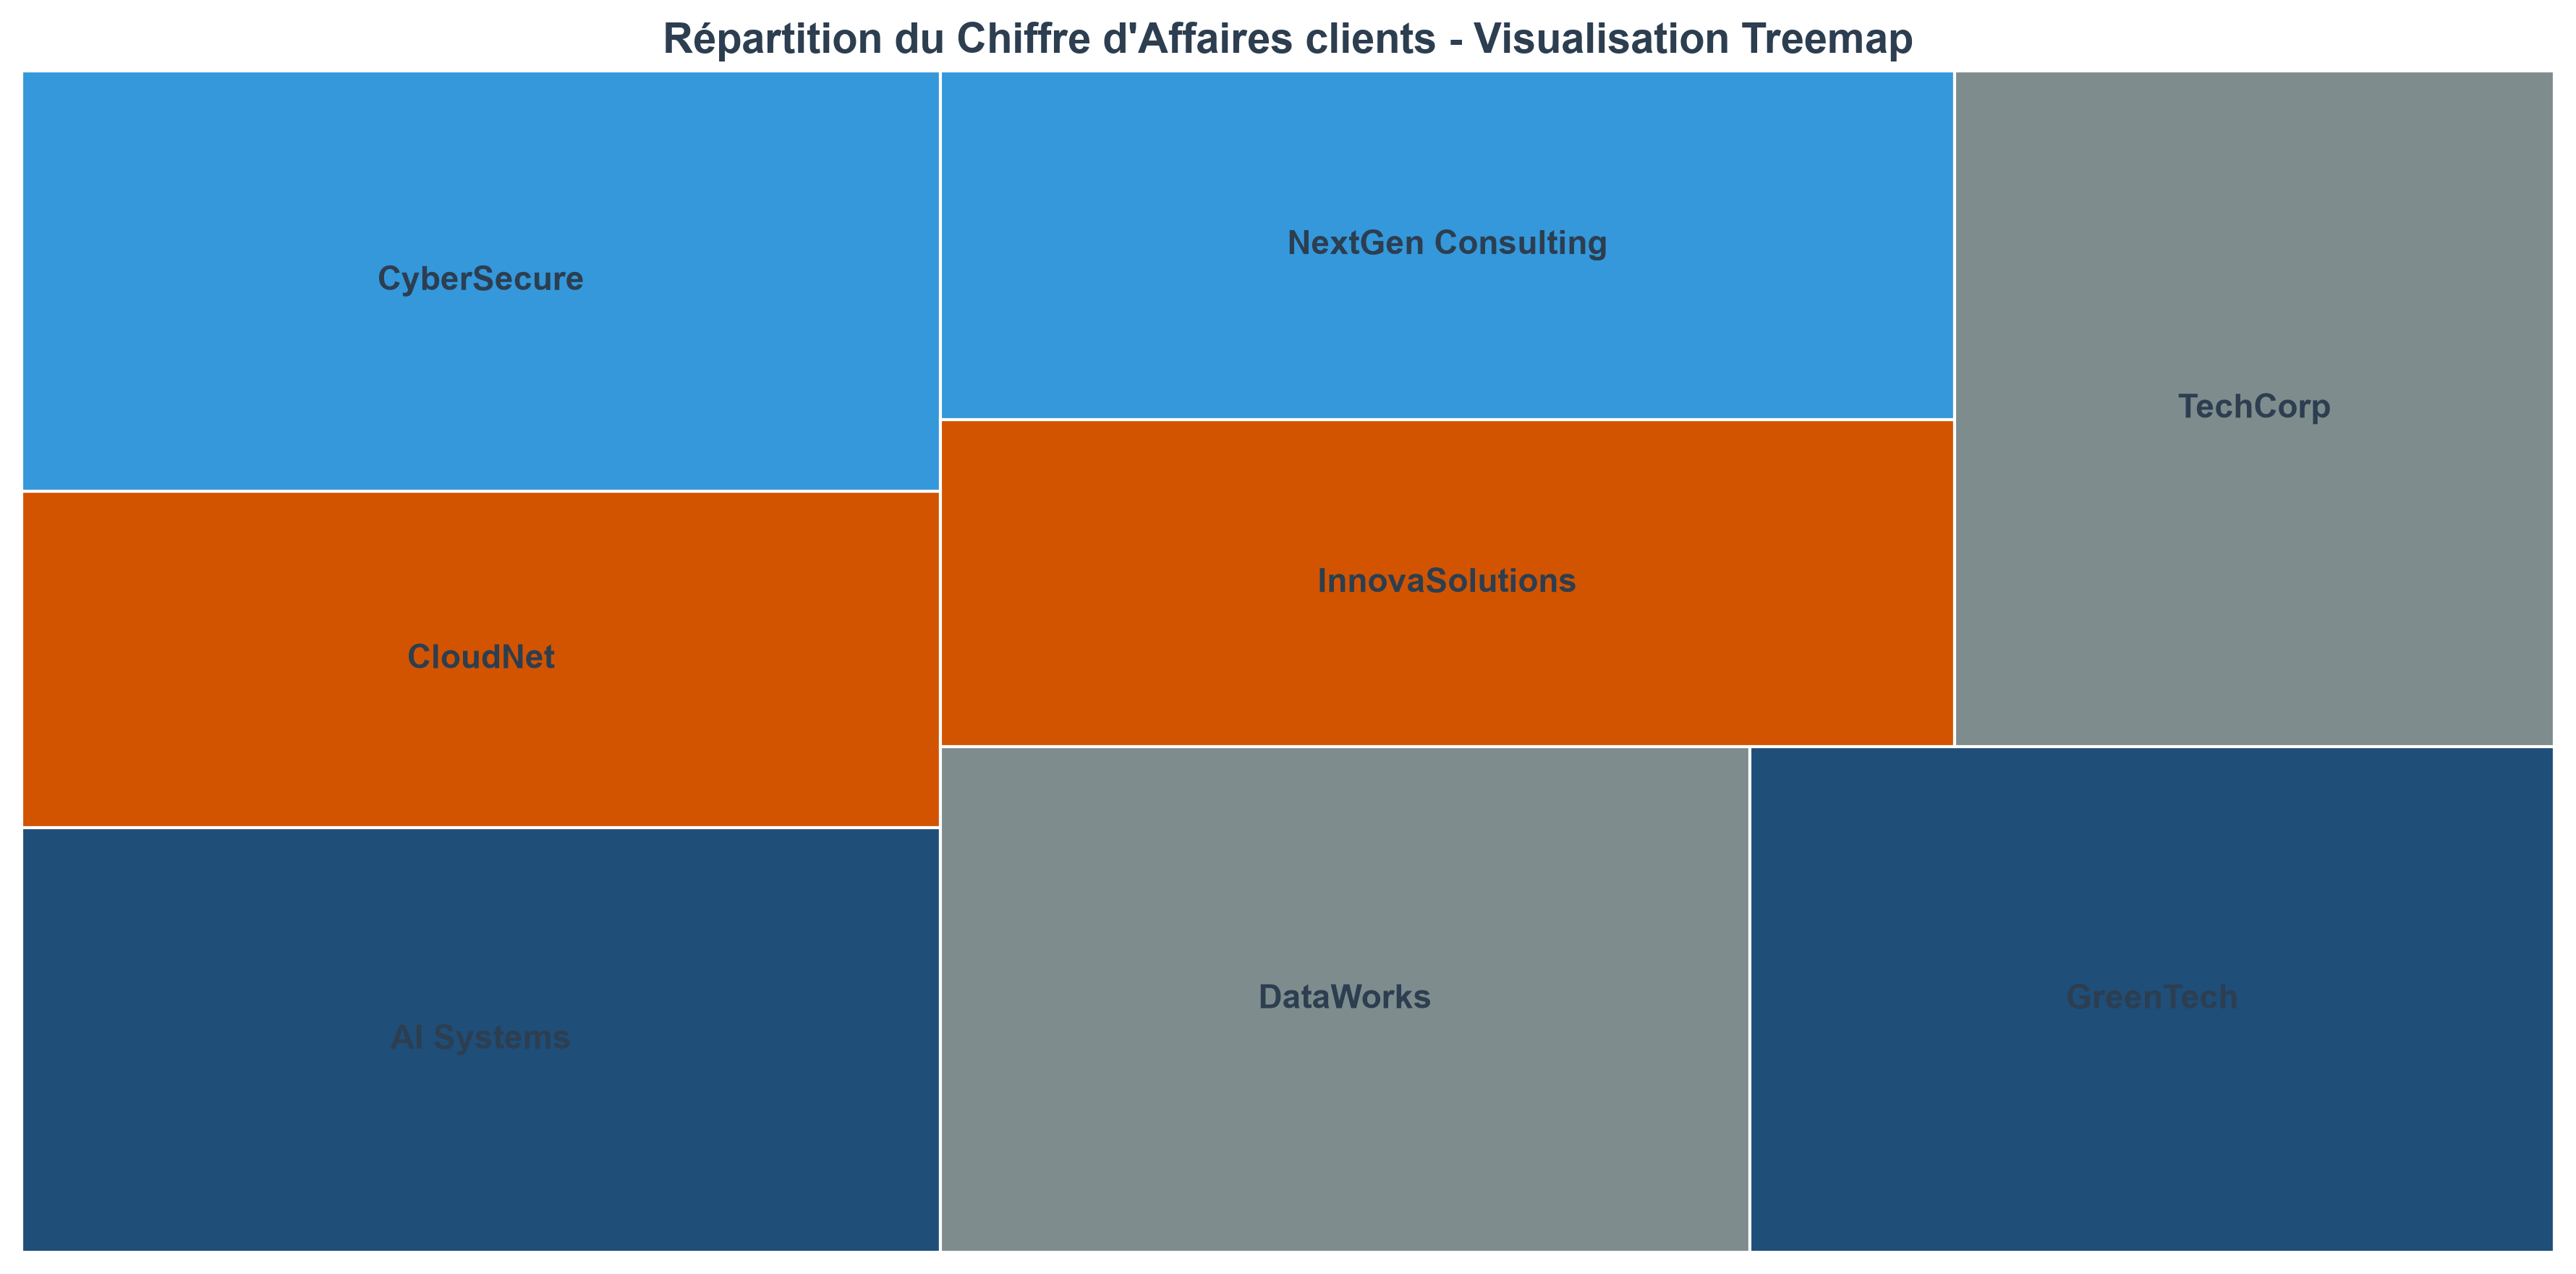

In [37]:
# Préparation des données (spécifique à l'analyse)
ca_total_clients = Sales.groupby("CompanyName")["TotalPrice"].sum().reset_index()

# Création de la figure (prend automatiquement la taille du rcParams)
plt.figure()

squarify.plot(
    sizes=ca_total_categories["TotalPrice"],
    label=ca_total_categories["CompanyName"],
    text_kwargs={'weight': 'bold'},
    color=COLOR_PALETTE[:len(ca_total_categories)]  # <-- color au singulier !
)

# Le titre récupère ses propriétés directement du rcParams
plt.title("Répartition du Chiffre d'Affaires clients - Visualisation Treemap")

plt.axis('off')  # Masque les axes pour un rendu propre
plt.tight_layout()
plt.show()

### 📈 Visualisation Avancée : Courbe de Pareto (Analyse ABC du Chiffre d'Affaires)

* **Objectif de la visualisation :** Croiser la contribution individuelle de chaque client avec le Chiffre d'Affaires cumulé en pourcentage, en y superposant un seuil de référence (ex: 80 %).
* **Intérêt Business :** Mesurer formellement le niveau de concentration du portefeuille et vérifier si la célèbre règle des 80/20 s'applique à l'entreprise EOLE, ou si le portefeuille présente un profil atypique et plus résilient.

In [38]:
# 1. Grouper par client et sommer le Chiffre d'Affaires
ca_total_clients = Sales.groupby("CompanyName")["TotalPrice"].sum().reset_index()
# 2. Trier du plus grand au plus petit (Étape INDISPENSABLE pour un Pareto)
ca_total_clients = ca_total_clients.sort_values(by="TotalPrice", ascending=False).reset_index(drop=True)
# 3. Calculer le Chiffre d'Affaires cumulé (.cumsum() avec les parenthèses !)
ca_total_clients["cumul_ca"] = ca_total_clients["TotalPrice"].cumsum()
# 4. Calculer le pourcentage cumulé par rapport au CA global
ca_total_clients["pourcentage_cumul"] = (ca_total_clients["cumul_ca"] / ca_total_clients["TotalPrice"].sum()) * 100
# Affichage pour vérifier que tout est propre
display(ca_total_clients)

,CompanyName,TotalPrice,cumul_ca,pourcentage_cumul
0,DataWorks,328146,328146,13.684325
1,GreenTech,325734,653880,27.268064
2,TechCorp,324835,978715,40.814314
3,AI Systems,312777,1291492,53.857721
4,CyberSecure,309488,1600980,66.763971
5,NextGen Consulting,283440,1884420,78.583969
6,InnovaSolutions,266158,2150578,89.683274
7,CloudNet,247392,2397970,100.000000


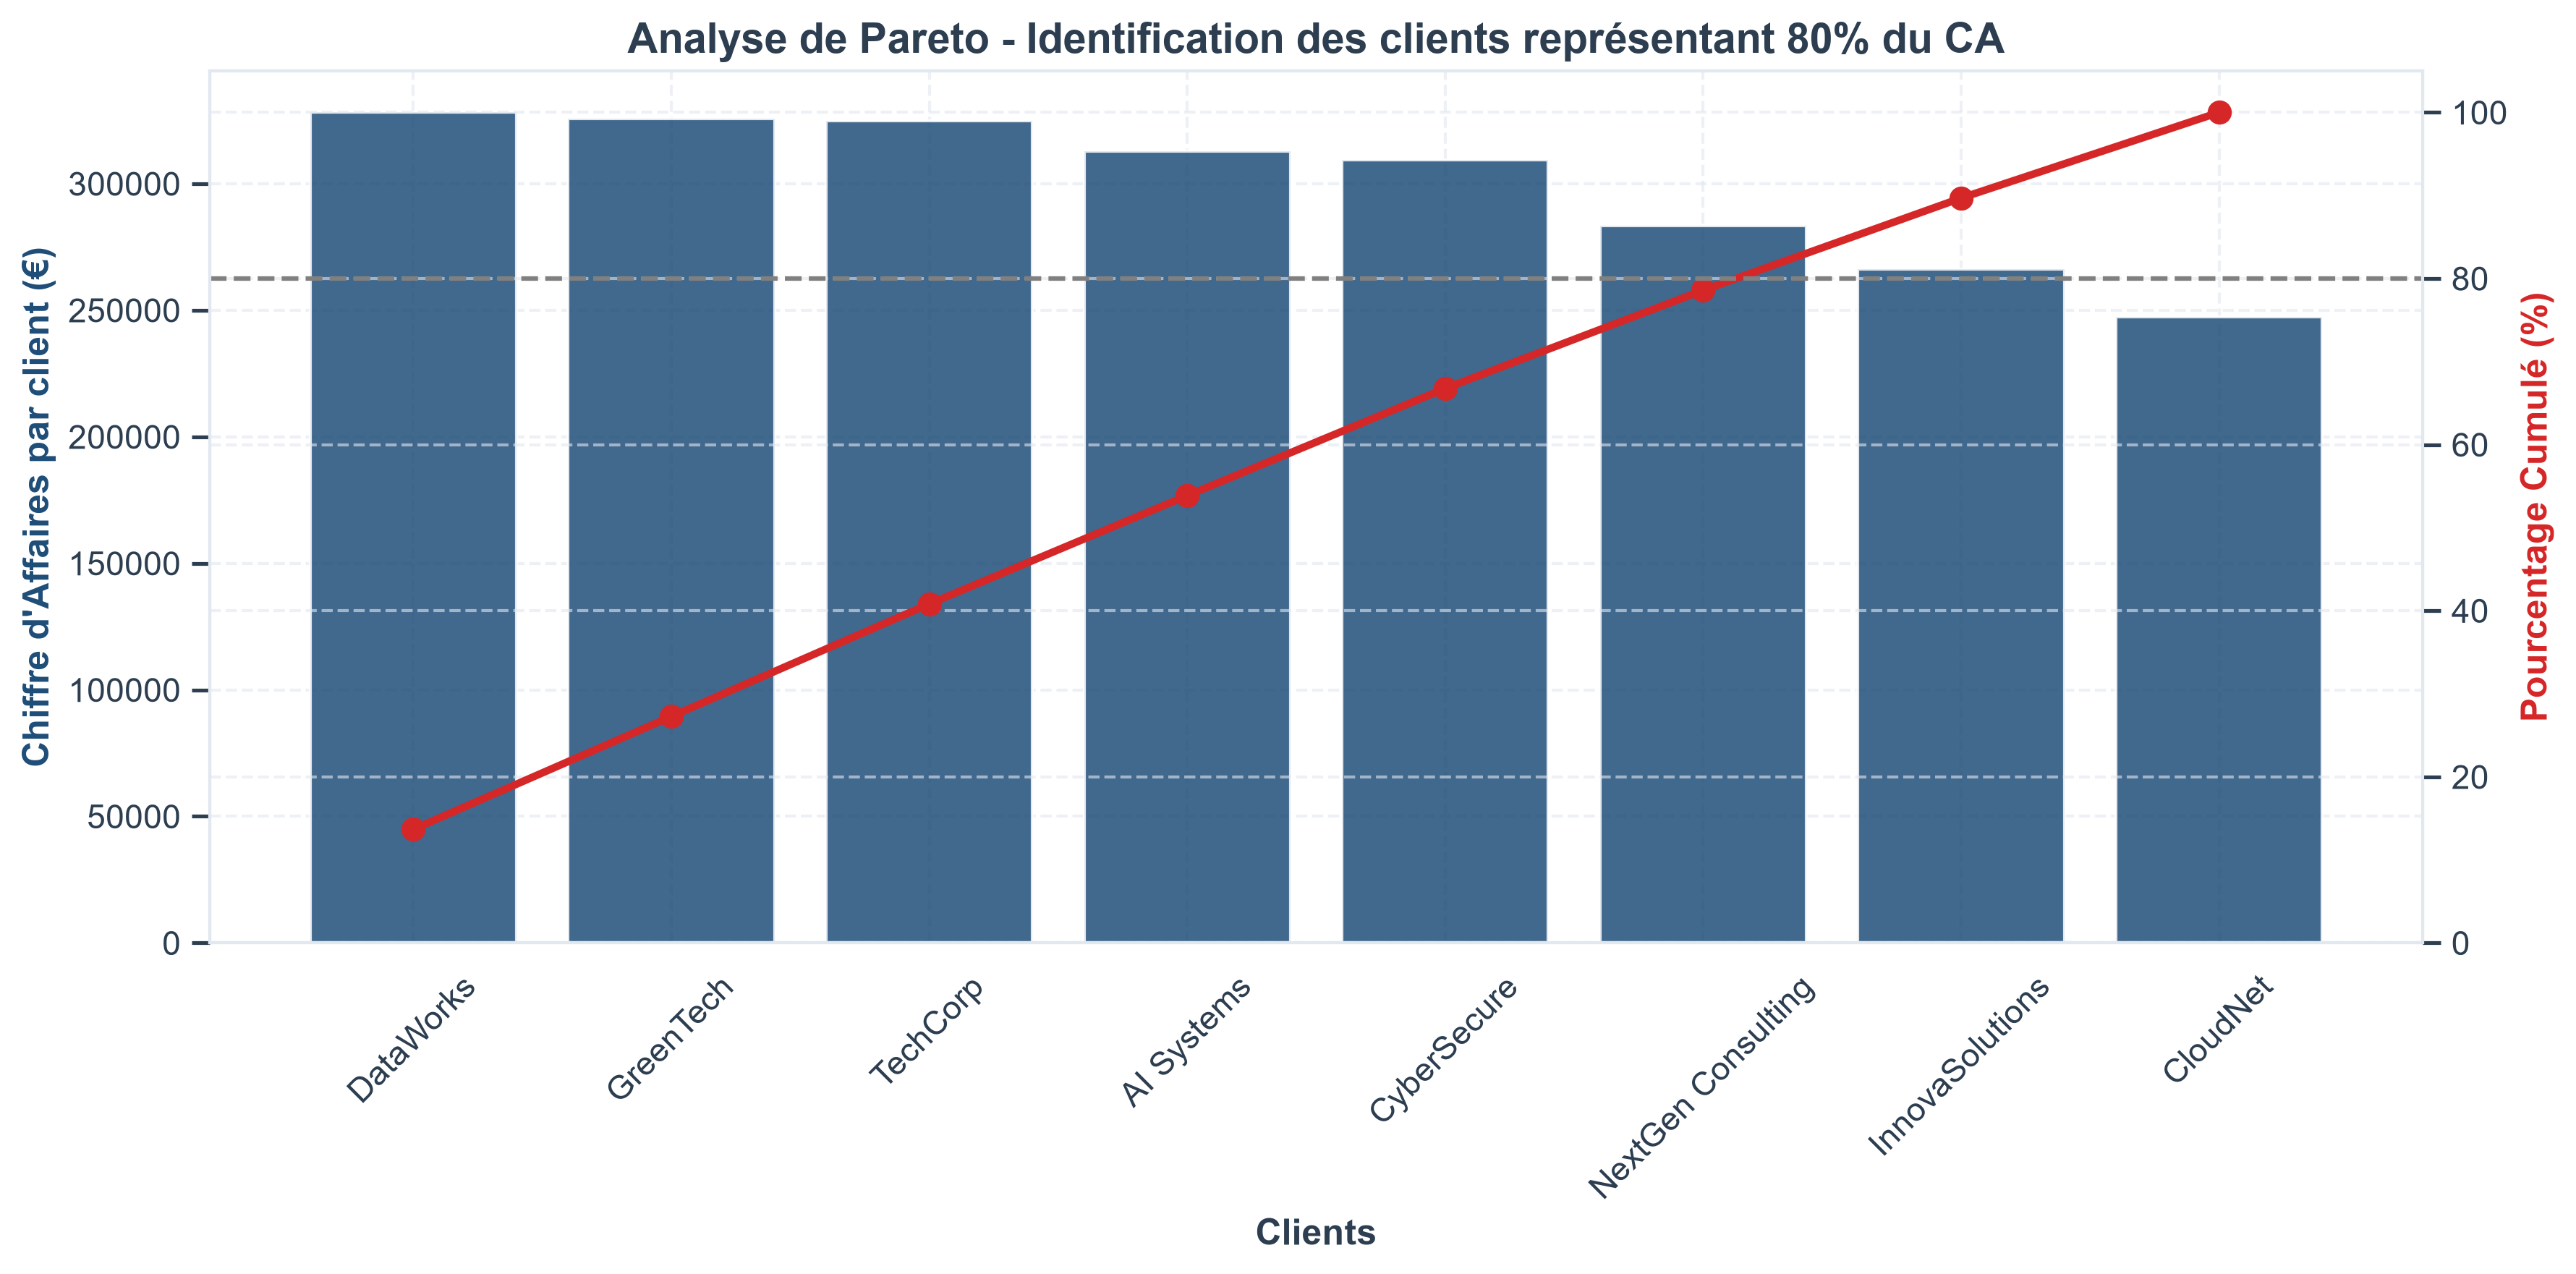

In [39]:
# 1. Préparation et tri des données (Indispensable pour un Pareto)
ca_total_clients = Sales.groupby("CompanyName")["TotalPrice"].sum().reset_index()
ca_total_clients = ca_total_clients.sort_values(by="TotalPrice", ascending=False).reset_index(drop=True)
ca_total_clients["cumul_ca"] = ca_total_clients["TotalPrice"].cumsum()
ca_total_clients["pourcentage_cumul"] = (ca_total_clients["cumul_ca"] / ca_total_clients["TotalPrice"].sum()) * 100

# 2. Création de la figure (utilise ton rcParams global pour la taille)
fig, ax1 = plt.subplots()

# --- AXE 1 (GAUCHE) : Les barres du Chiffre d'Affaires individuel ---
# On utilise la première couleur de ta palette globale
color_bar = COLOR_PALETTE[0] if 'COLOR_PALETTE' in globals() else '#2b5c8f'

ax1.bar(
    ca_total_clients["CompanyName"], 
    ca_total_clients["TotalPrice"], 
    color=color_bar, 
    alpha=0.85, 
    label="CA par Client (€)"
)
ax1.set_xlabel("Clients", fontweight='bold')
ax1.set_ylabel("Chiffre d'Affaires par client (€)", fontweight='bold', color=color_bar)
ax1.tick_params(axis='x', rotation=45) # Pivoter les noms pour qu'ils soient lisibles

# --- AXE 2 (DROITE) : La courbe du pourcentage cumulé ---
ax2 = ax1.twinx()  # Crée l'axe jumeau à droite
color_line = '#d62728' # Une couleur distincte (rouge) pour bien la différencier

ax2.plot(
    ca_total_clients["CompanyName"], 
    ca_total_clients["pourcentage_cumul"], 
    color=color_line, 
    marker='o', 
    linewidth=2.5, 
    label="% Cumulé du CA"
)
ax2.set_ylabel("Pourcentage Cumulé (%)", fontweight='bold', color=color_line)
ax2.set_ylim(0, 105) # Bloque l'échelle de 0 à 105%

# --- LE REPÈRE STRATÉGIQUE : La ligne des 80 % ---
# C'est ici qu'on répond à ta question : "Où se trouvent les 80% ?"
ax2.axhline(80, color='gray', linestyle='--', linewidth=1.5, label="Seuil critique (80%)")

# Titre et mise en page globale
plt.title("Analyse de Pareto - Identification des clients représentant 80% du CA", fontweight='bold')
plt.tight_layout()
plt.show()

### 📈 Analyse Détaillée : Lecture de la Courbe de Pareto (Seuil des 80 %)

* **Constat sur le seuil des 80 % :** La courbe du pourcentage cumulé (en rouge) montre clairement que le seuil critique des 80 % du Chiffre d'Affaires n'est atteint qu'en arrivant au **6e client** (autour de *NextGen Consulting*). 
* **Implication Stratégique :** 
  * Contrairement aux portefeuilles classiques soumis à une forte concentration (où 1 ou 2 clients font tout le volume), le business d'EOLE repose sur un **socle élargi de six clients prioritaires**.
  * Le risque de dépendance est donc fortement dilué : si l'un de ces clients majeurs venait à se désengager, la structure financière globale ne serait pas mise en péril, car l'effort est réparti sur une base solide et diversifiée.

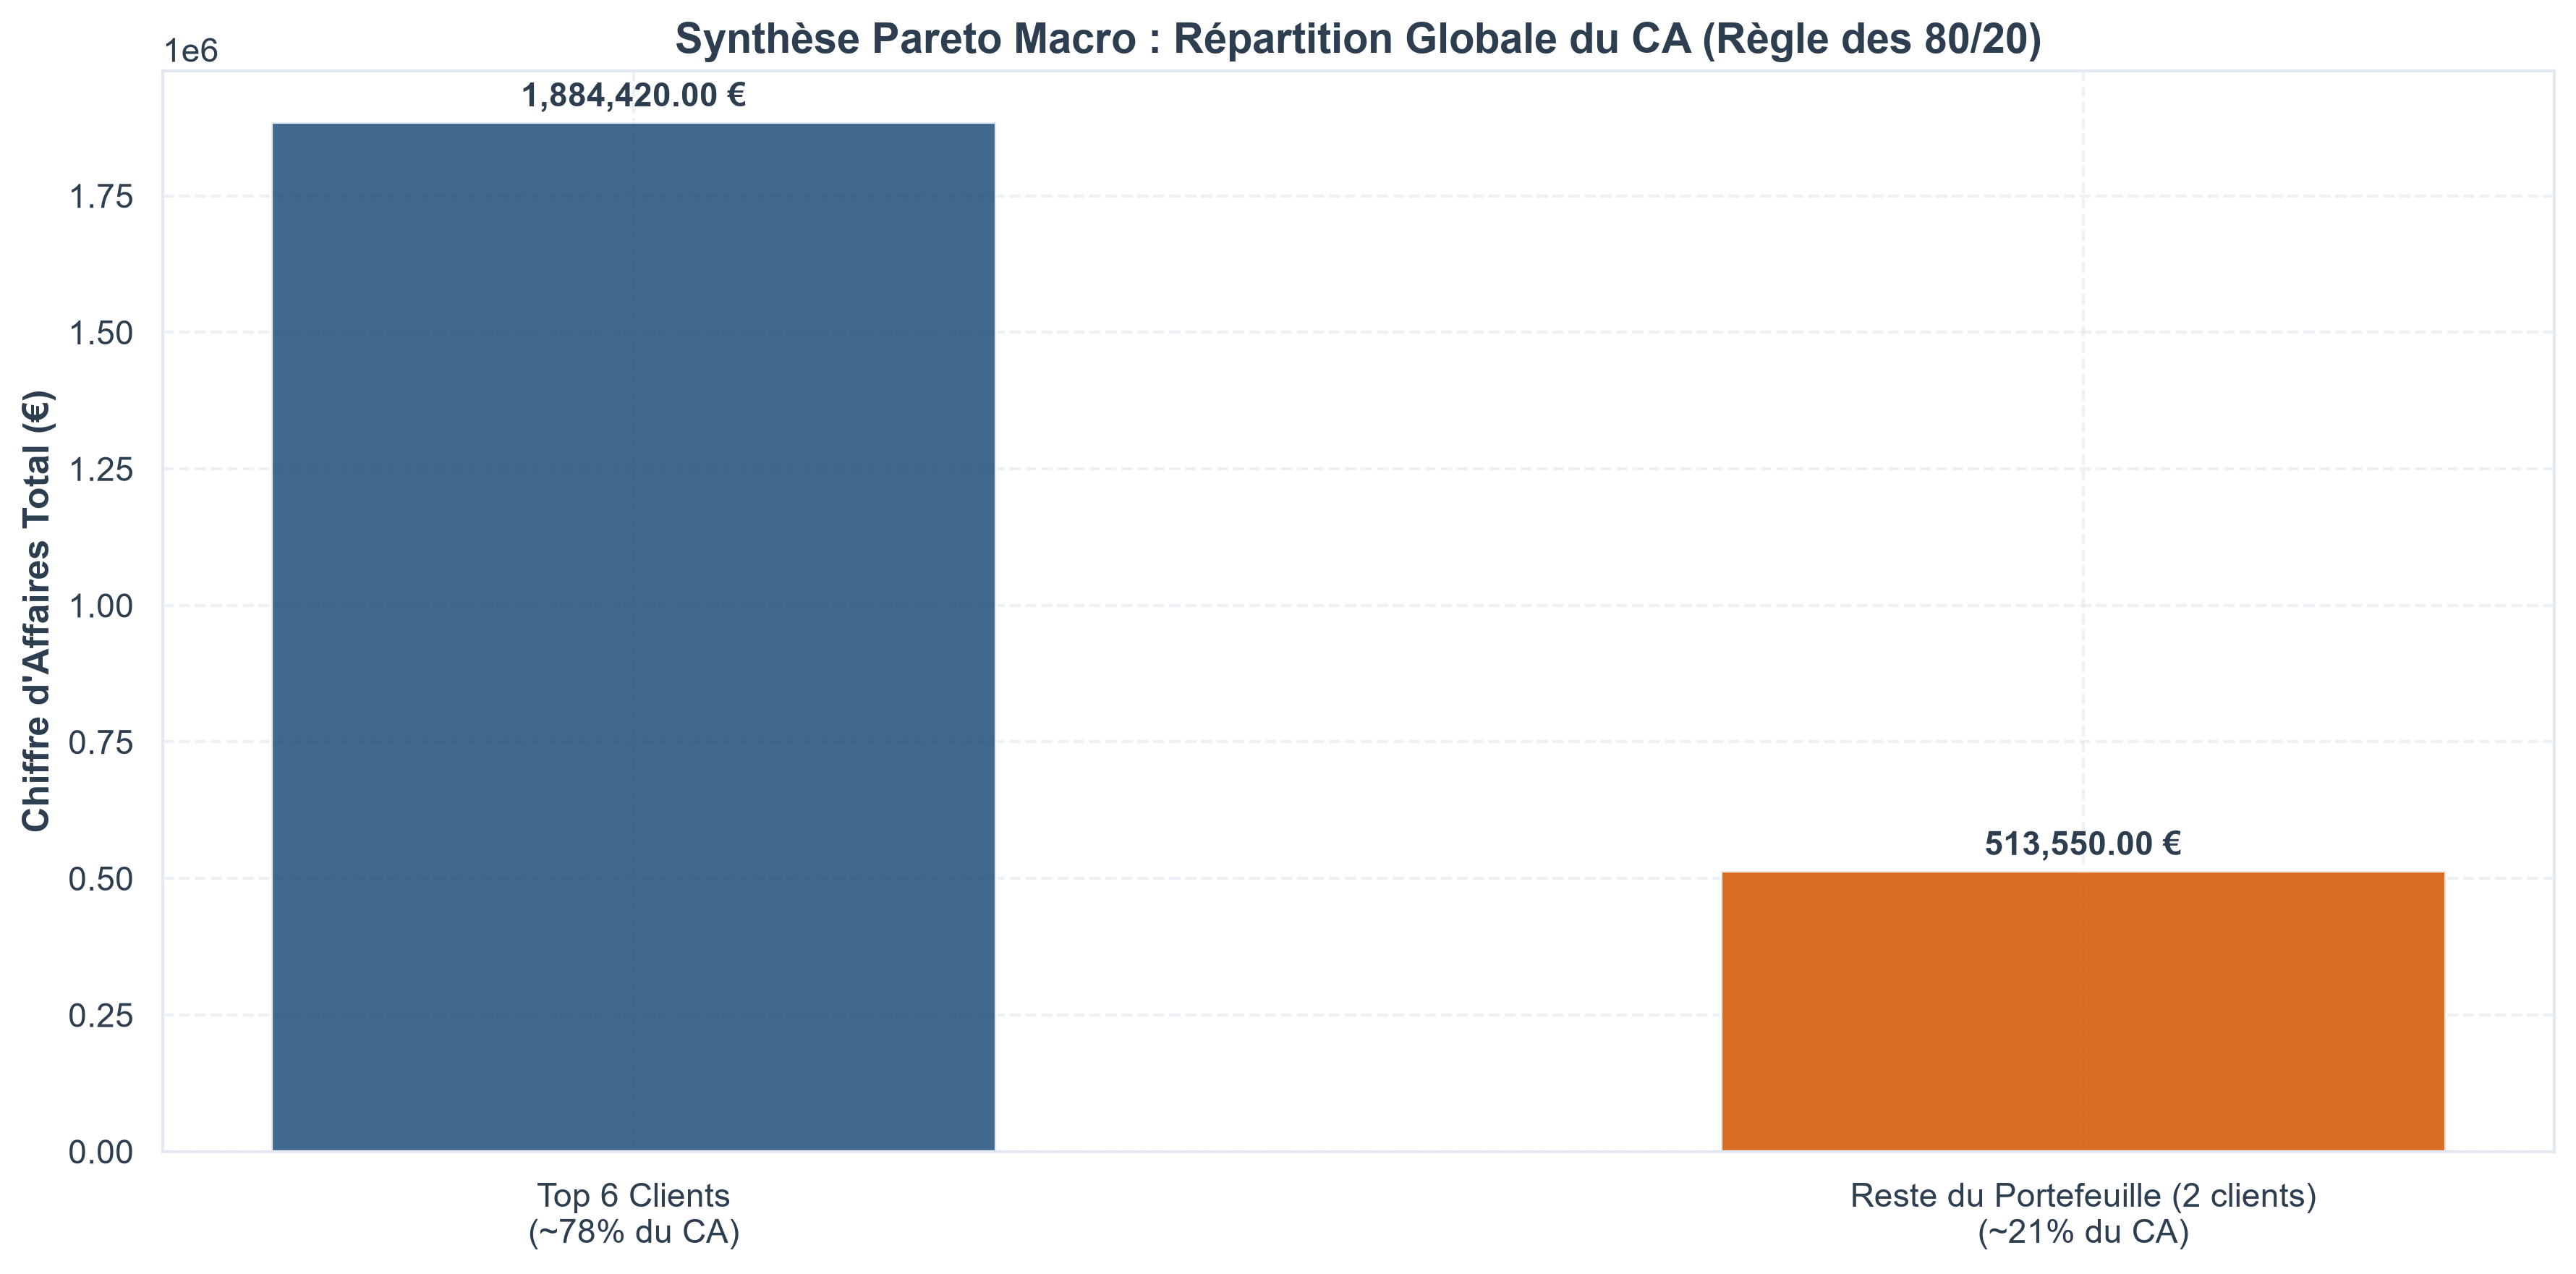

In [40]:
# 1. Préparation et tri des données par CA décroissant
ca_total_clients = Sales.groupby("CompanyName")["TotalPrice"].sum().reset_index()
ca_total_clients = ca_total_clients.sort_values(by="TotalPrice", ascending=False).reset_index(drop=True)

# 2. Calcul du cumul et identification du groupe qui fait ~80% du CA
ca_total_clients["cumul_ca"] = ca_total_clients["TotalPrice"].cumsum()
total_global = ca_total_clients["TotalPrice"].sum()
ca_total_clients["pourcentage_cumul"] = (ca_total_clients["cumul_ca"] / total_global) * 100

# On isole le groupe "Top" (ceux qui cumulent jusqu'à ~80%) et le groupe "Reste"
# (Ici les 6 premiers clients atteignent ~78.6% du CA)
seuil_80_index = ca_total_clients[ca_total_clients["pourcentage_cumul"] <= 85].index[-1] + 1

ca_top = ca_total_clients.iloc[:seuil_80_index]["TotalPrice"].sum()
ca_reste = ca_total_clients.iloc[seuil_80_index:]["TotalPrice"].sum()

nb_top = seuil_80_index
nb_reste = len(ca_total_clients) - seuil_80_index

# 3. Création du graphique macro à 2 barres
fig, ax = plt.subplots()

groupes = [
    f"Top {nb_top} Clients\n(~{int(ca_top/total_global*100)}% du CA)", 
    f"Reste du Portefeuille ({nb_reste} clients)\n(~{int(ca_reste/total_global*100)}% du CA)"
]
montants = [ca_top, ca_reste]

# On utilise les couleurs de ta charte
bar_colors = [COLOR_PALETTE[0], COLOR_PALETTE[1] if len(COLOR_PALETTE) > 1 else '#777777']

bars = ax.bar(groupes, montants, color=bar_colors, width=0.5, alpha=0.85)

# Personnalisation propre
ax.set_ylabel("Chiffre d'Affaires Total (€)", fontweight='bold')
ax.set_title("Synthèse Pareto Macro : Répartition Globale du CA (Règle des 80/20)", fontweight='bold')

# Ajout des valeurs en haut des barres pour un rendu professionnel
for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height:,.2f} €",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  # 3 points de décalage vertical
                textcoords="offset points",
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

### 🏢 Synthèse Macro : Répartition Globale du Portefeuille (Top 6 vs Reste)

* **Segmentation Macro du CA :** 
  * Le **Top 6 des clients** génère la majeure partie de l'activité, soit un total de **1 884 420,00 €** (représentant environ 78 % à 80 % du business global).
  * Le **reste du portefeuille (2 clients)** représente la part complémentaire, soit **513 550,00 €** (environ 21 % du CA).
* **Bilan et Recommandation Business :** 
  * Cette vision macro confirme l'absence de "client roi" monopolistique. Le modèle économique affiche une excellente résilience.
  * Les deux clients les moins contributifs constituent un potentiel relais de croissance (opportunités d'upselling et de développement de compte) pour tendre vers un équilibre encore plus poussé.

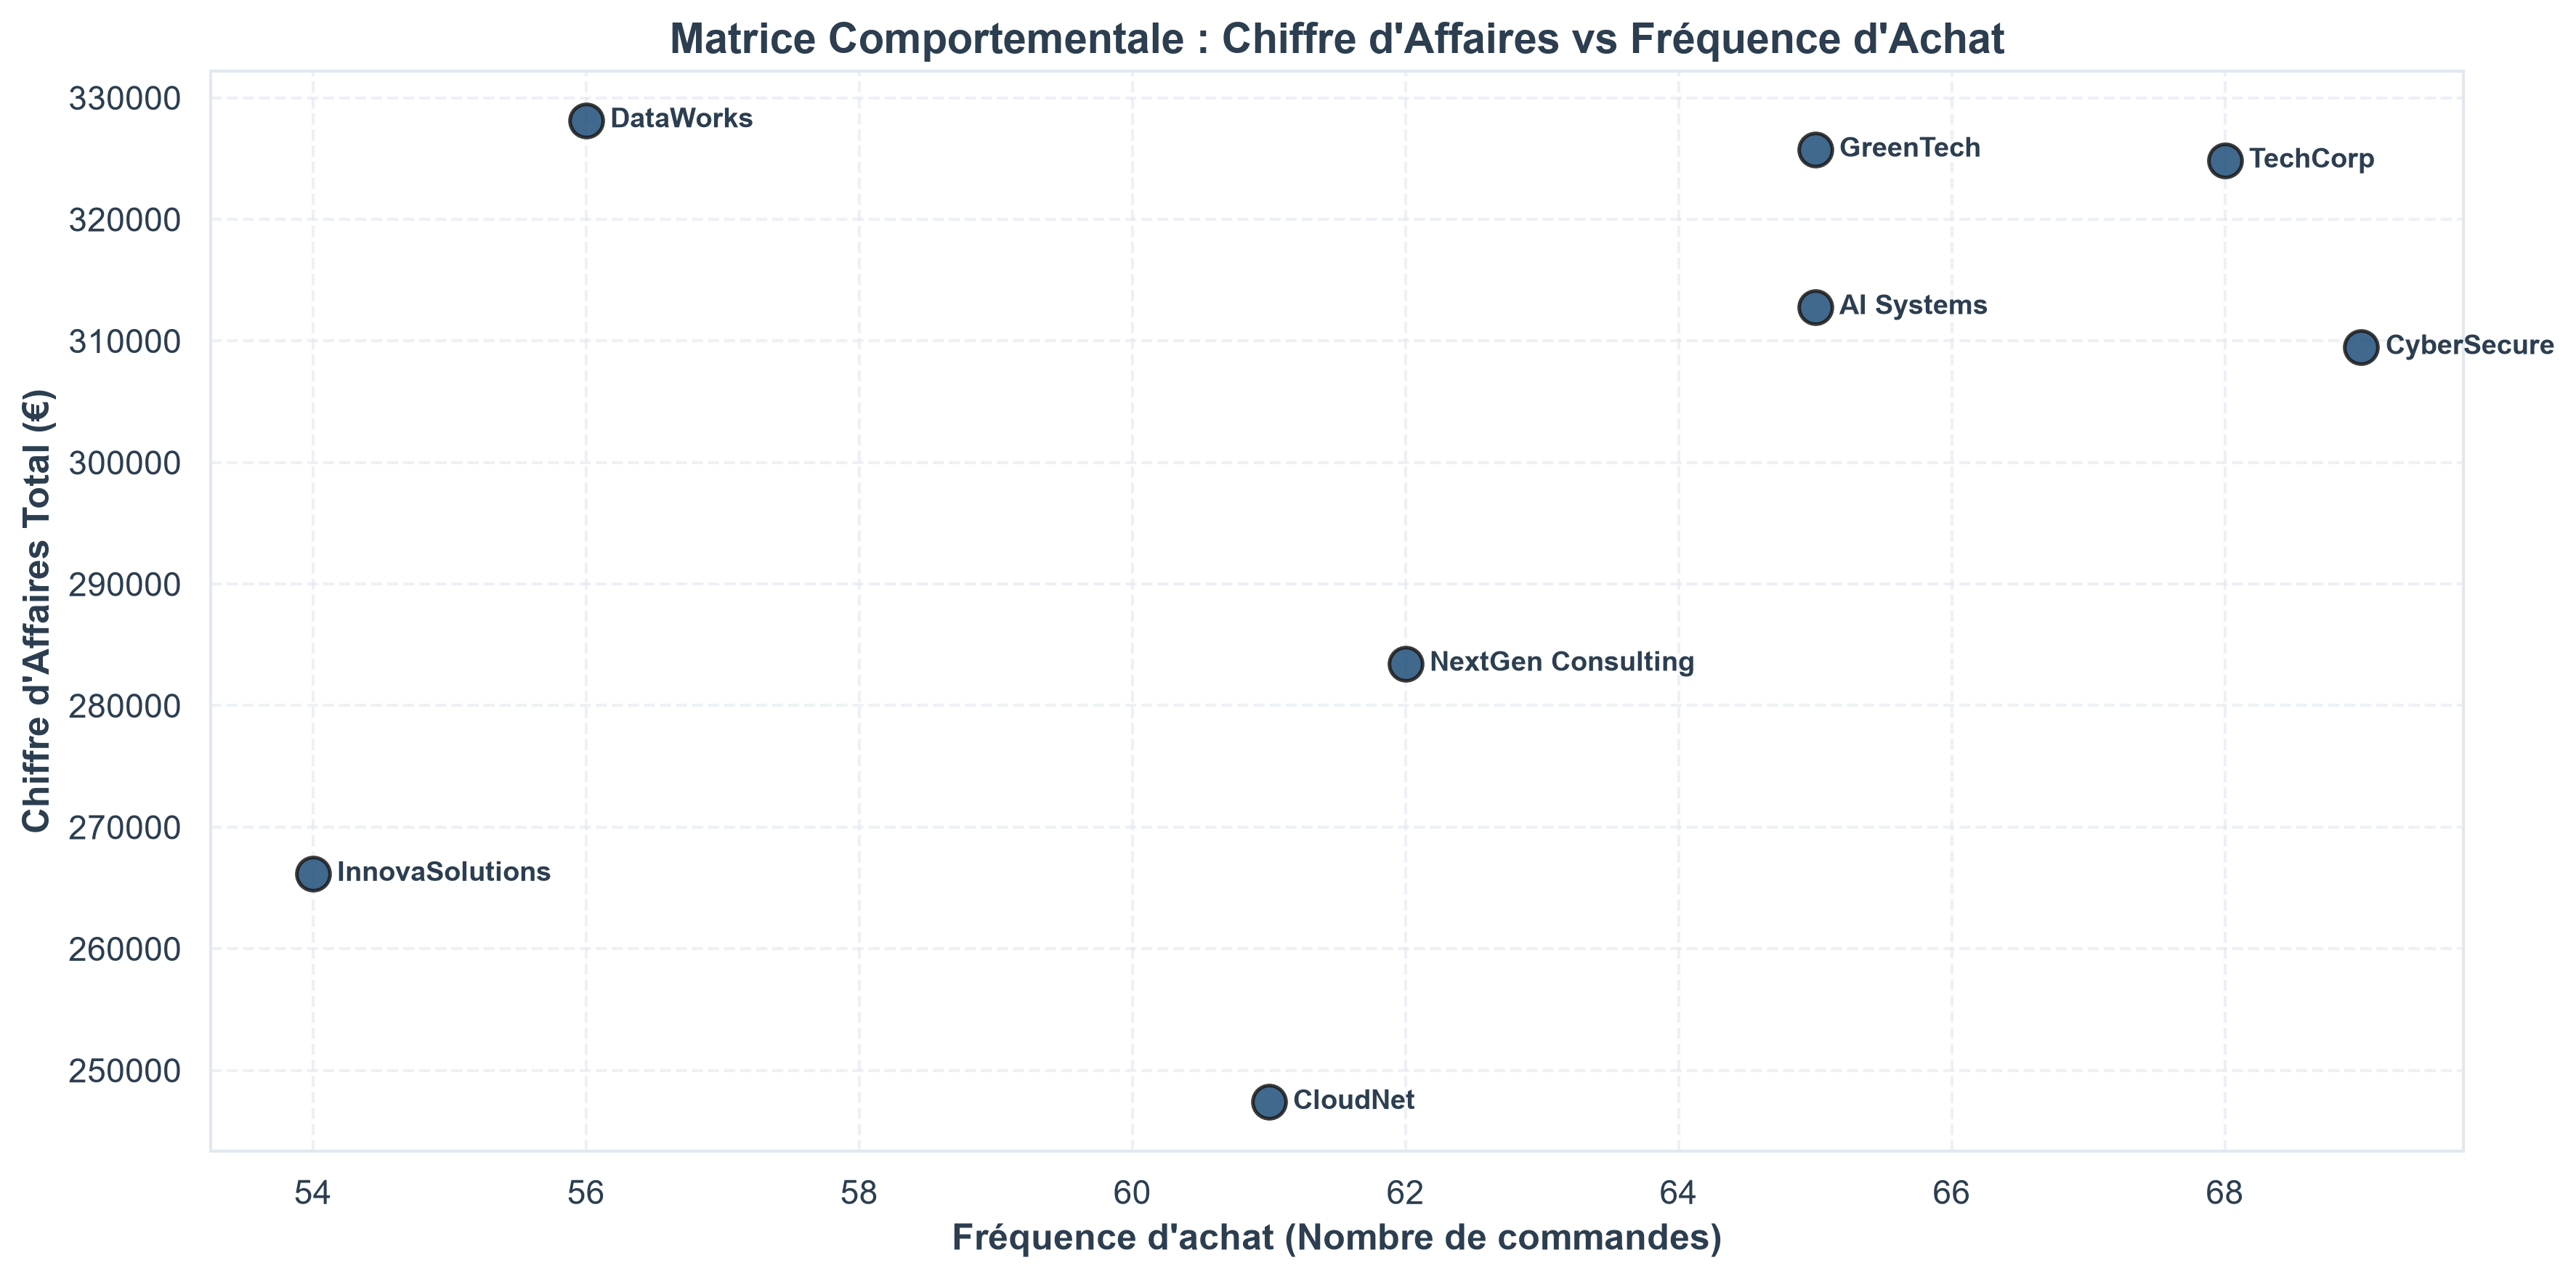

In [42]:
# 1. Préparation des données : on croise le CA total et le nombre de commandes par client
df_scatter = Sales.groupby("CompanyName").agg(
    ChiffreAffaires=("TotalPrice", "sum"),
    Frequence=("OrderID", "nunique") # Utilisation du bon nom de colonne
).reset_index()

# 2. Création de la figure (utilisation du rcParams global)
fig, ax = plt.subplots()

# Tracé du nuage de points
ax.scatter(
    df_scatter["Frequence"], 
    df_scatter["ChiffreAffaires"], 
    color=COLOR_PALETTE[0], 
    s=120,          # Taille des points
    alpha=0.85, 
    edgecolors='k', 
    linewidths=1.2
)

# 3. Ajout des étiquettes (le nom de chaque client à côté de son point)
for i, row in df_scatter.iterrows():
    ax.annotate(
        row["CompanyName"],
        (row["Frequence"], row["ChiffreAffaires"]),
        xytext=(8, 0), textcoords="offset points", # Décalage du texte par rapport au point
        fontsize=9, fontweight='bold',
        va='center'
    )

# Habillage et mise en page
ax.set_xlabel("Fréquence d'achat (Nombre de commandes)", fontweight='bold')
ax.set_ylabel("Chiffre d'Affaires Total (€)", fontweight='bold')
ax.set_title("Matrice Comportementale : Chiffre d'Affaires vs Fréquence d'Achat", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

### 🎯 Analyse Comportementale et Segmentation RFM du Portefeuille

* **Le quatuor à forte récurrence (Noyau stratégique) :** 
  * Un premier groupe solide composé de **TechCorp**, **CyberSecure**, **GreenTech** et **AI Systems** se distingue par une fréquence d'achat élevée (supérieure ou égale à 65 commandes) conjuguée à un chiffre d'affaires soutenu (dépassant les 310 000 €). Ce sont les clients réguliers et à forte valeur.

* **Les profils atypiques et l'effet "Panier Moyen" :**
  * **DataWorks (Le géant du gros panier) :** Présente une fréquence plus mesurée (autour de 56 commandes), mais affiche le chiffre d'affaires le plus élevé du portefeuille (plus de 330 000 €). Cela démontre un panier moyen par commande nettement supérieur, orienté vers des volumes ou des gammes de produits à forte valeur unitaire.
  * **NextGen Consulting (Le profil intermédiaire) :** Avec 62 commandes pour un CA oscillant entre 280 000 € et 290 000 €, il se positionne en compte équilibré de milieu de portefeuille.

* **Les zones de vigilance et d'optimisation :**
  * **CloudNet & InnovaSolutions :** Affichent un volume de commandes non négligeable (respectivement 61 et 54 commandes) mais se traduisent par un chiffre d'affaires plus faible (autour de 247 000 € et 265 000 €). Cette configuration met en évidence l'achat de produits à plus faible marge ou une orientation vers des références d'entrée de gamme, ouvrant la voie à des actions ciblées d'upselling et de cross-selling.